---
title: "American Time Use Survey: Analytical Exploration"
subtitle: "Time Allocation, trends, and Comparisons"
author: "Maxwell Taylor"
date: last-modified

format:
  html:
    toc: true
    toc-depth: 3
    toc-location: right
    number-sections: true
    code-fold: true
    code-tools: true
    code-overflow: scroll

execute:
  echo: true
  warning: true
  message: false
---


In [1]:
# Load packages
library(tidyverse)
library(ggplot2)
library(ggthemes)
library(plotly)

# Load prepared respondant-level data
atus_full <- readRDS("data/processed/atus_full.rds")

# Load reference tables
activity_inventory <- readRDS("data/processed/activity_inventory.rds")
activity_profile <- readRDS("data/processed/activity_profile.rds")
resp_inventory <- readRDS("data/processed/resp_inventory.rds")

Warning message:
"package 'ggplot2' was built under R version 4.6.2"
── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.4     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Warning message:
"package 'ggthemes' was built under R version 4.6.2"

Attaching package: 'plotly'


The following object is masked from 'package:ggplot2':

    last_plot


The following object is masked from 'package:stats':

    filter


The following object is masked from 'package:graphics':

    layout




In [2]:
atus_analysis <- atus_full |>
  # As mentioned in explore_atus, 2020 is missing data due to the pandemic
  filter(TUYEAR != 2020)

# Verify survey weights by year as described on
# https://www.bls.gov/tus/other-documentation/howto.htm
atus_analysis |>
  group_by(TUYEAR) |>
  summarize(
    n = n(),
    missing_weights = sum(is.na(TUFNWGTP)),
    nonpositive_weights = sum(TUFNWGTP <= 0, na.rm = TRUE),
    min_weights = min(TUFNWGTP, na.rm = TRUE),
    max_weight = max(TUFNWGTP, na.rm = TRUE),
    .groups = "drop"
  )

TUYEAR,n,missing_weights,nonpositive_weights,min_weights,max_weight
<dbl>,<int>,<int>,<int>,<dbl>,<dbl>
2003,20720,0,0,419471.7,43966142
2004,13973,0,0,524784.5,61990731
2005,13038,0,0,570032.3,79557282
2006,12943,0,0,507201.0,83364095
2007,12248,0,0,608478.6,80213705
2008,12723,0,0,635591.4,97493539
2009,13133,0,0,571108.7,86519122
2010,13260,0,0,498807.0,78237219
2011,12479,0,0,786230.5,90644298


In [3]:
# Group activity codes by tier
tier1_codes <- split(
  activity_inventory$code,
  activity_inventory$tier_1
)

# Examine results
names(tier1_codes)
# Analysis\Data\Raw\lexiconnoex0325.pdf
# Unclear why no 17
# 50 means "unable to code"

tier1_codes[["01"]] # ALL personal care activity codes
tier1_codes[["02"]] # All household activity codes
# etc.

[1] "01" "02" "03" "04" "05" "06" "07" "08" "09" "10" "11" "12" "13" "14" "15"
[16] "16" "18" "50"

[1] "t010101" "t010102" "t010199" "t010201" "t010299" "t010301" "t010399"
 [8] "t010401" "t010499" "t010501" "t010599" "t019999"

[1] "t020101" "t020102" "t020103" "t020104" "t020199" "t020201" "t020202"
 [8] "t020203" "t020299" "t020301" "t020302" "t020303" "t020399" "t020401"
[15] "t020402" "t020499" "t020501" "t020502" "t020599" "t020681" "t020699"
[22] "t020701" "t020799" "t020801" "t020899" "t020901" "t020902" "t020903"
[29] "t020904" "t020905" "t020999" "t029999"

In [4]:
# Check data completeness
activity_profile |>
  filter(n_missing > 0 | n_negative > 0) # 0 rows, so complete

code,n_positive,pct_positive,n_missing,n_negative,n_distinct,tier_1,tier_2,tier_3
<chr>,<int>,<dbl>,<int>,<int>,<int>,<chr>,<chr>,<chr>


In [5]:
# Respondent-level activity summary

# Retain respondent characteristics
atus_tier1 <- atus_analysis |>
  select(
    # Using Analysis\Data\Raw\atuscpscodebk0325.pdf,
    # Analysis\Data\Raw\atusintcodebk0325.pdf,
    # Analysis\Data\Raw\atusintcodebk0325.interview.pdf
    TUCASEID, # Respondant ID
    TUYEAR, # Year
    TUFNWGTP, # ATUS Final Weight
    TEAGE, # Age
    TESEX, # Sex
    PEEDUCA, # Highest Education
    TELFS, # Labor Force Status
    TESCHENR, # School Enrolment
    TUDIARYDAY # Day of the week, 1 = sunday
  )

# Calculate total minutes for each broad activity category
for (code in names(tier1_codes)) {
  column_name <- paste0("code_", code)
  atus_tier1[[column_name]] <- rowSums(
    atus_analysis |>
      select(all_of(tier1_codes[[code]]))
  )
}

dim(atus_tier1)
head(atus_tier1)
# ID, Year, Weight, et., + total per tier

[1] 250172     27

TUCASEID,TUYEAR,TUFNWGTP,TEAGE,TESEX,PEEDUCA,TELFS,TESCHENR,TUDIARYDAY,code_01,⋯,code_09,code_10,code_11,code_12,code_13,code_14,code_15,code_16,code_18,code_50
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
20030100013280,2003,8155463,60,1,44,2,-1,6,910,⋯,0,0,5,325,200,0,0,0,0,0
20030100013344,2003,1735323,41,2,40,1,2,7,680,⋯,0,0,90,590,0,0,0,0,20,0
20030100013352,2003,3830527,26,2,41,2,2,7,640,⋯,0,0,75,340,0,0,0,60,10,0
20030100013848,2003,6622023,36,2,39,4,2,5,755,⋯,0,0,25,265,0,0,0,0,0,0
20030100014165,2003,3068387,51,1,45,1,-1,5,460,⋯,0,0,92,60,60,0,0,0,78,0
20030100014169,2003,3455425,32,2,43,2,1,5,710,⋯,0,0,65,305,0,0,0,0,0,0


In [6]:
# Validate via 24 hours = 1,440 minutes
tier1_columns <- paste0("code_", names(tier1_codes))

atus_tier1 <- atus_tier1 |>
  mutate(
    total_minutes = rowSums(pick(all_of(tier1_columns)))
  )

summary(atus_tier1$total_minutes) # All = 1440, correct

atus_tier1 |>
  count(total_minutes, sort = TRUE)

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   1440    1440    1440    1440    1440    1440 

total_minutes,n
<dbl>,<int>
1440,250172


In [7]:
# Annual time allocation
annual_tier1 <- atus_tier1 |>
  group_by(TUYEAR) |>
  summarise(
    across(
      all_of(tier1_columns),
      ~ weighted.mean(.x, TUFNWGTP) # "~" = short anonymous function so can use weight not just mean,
      # .x = currenty activity column, TUFNWGTP = survey weights
    ),
    .groups = "drop"
  )

annual_tier1

TUYEAR,code_01,code_02,code_03,code_04,code_05,code_06,code_07,code_08,code_09,code_10,code_11,code_12,code_13,code_14,code_15,code_16,code_18,code_50
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
2003,559.5843,111.5629,28.24835,11.450819,204.0595,25.97261,24.18782,5.640706,1.2490996,0.2961533,65.21080,273.2314,19.68504,8.413091,8.227885,7.272915,77.26434,8.442139
2004,559.0136,109.7442,28.74199,11.445622,202.7558,26.54410,24.38954,5.402653,0.9730729,0.3698816,66.91607,278.1325,19.47099,7.237597,8.704771,6.977864,76.05553,7.124166
2005,564.7037,111.1541,27.24279,9.813293,204.3886,24.28474,24.44363,5.008196,0.9564192,0.5186642,67.14910,273.5299,19.37811,7.533767,8.477486,6.526713,75.54829,9.342544
2006,563.6912,109.3251,26.93028,8.987865,207.2258,27.39149,24.24894,5.176084,1.0805362,0.6259569,66.79014,271.7257,18.93053,7.242039,7.781886,7.060324,74.58596,11.200181
2007,558.8140,112.1468,27.27093,8.204052,211.6956,23.99400,23.67603,5.240873,0.8692181,0.3344825,66.76128,271.3480,20.81874,8.856626,9.415468,6.469727,73.63578,10.448395
2008,562.7069,106.1814,27.01418,9.773106,207.2270,26.35128,22.89847,4.921706,0.8195097,0.4257962,66.60472,277.3858,19.92971,8.564216,8.818611,7.682013,71.86087,10.834754
2009,565.9398,109.8448,27.71385,8.548220,195.2846,26.11124,22.69660,5.150859,0.8304836,0.3823639,66.50776,281.3668,20.03407,8.718809,9.054306,6.839166,71.94986,13.026490
2010,567.2746,109.1821,25.88862,9.005842,193.3141,26.71183,22.36174,4.796836,0.9123629,0.5374074,67.71502,277.6236,20.03722,9.338732,9.026789,6.269629,71.47867,18.524938
2011,568.4044,107.0069,25.63378,8.798730,197.4860,26.34663,22.22086,4.397645,0.7615752,0.3511717,67.49705,279.0904,20.25816,9.297829,8.904178,5.821289,72.49685,15.226529


In [8]:
# Mutate for easier visualization:

annual_tier1_long <- annual_tier1 |>
  pivot_longer(
    cols = all_of(tier1_columns),
    names_to = "activity",
    values_to = "mean_minutes"
  ) |>
  mutate(
    mean_hours = mean_minutes / 60
  )

dim(annual_tier1_long)
head(annual_tier1_long)

[1] 396   4

TUYEAR,activity,mean_minutes,mean_hours
<dbl>,<chr>,<dbl>,<dbl>
2003,code_01,559.58434,9.3264057
2003,code_02,111.56292,1.8593820
2003,code_03,28.24835,0.4708058
2003,code_04,11.45082,0.1908470
2003,code_05,204.05954,3.4009923
2003,code_06,25.97261,0.4328769


In [9]:
# Activity labels
tier1_labels <- tribble(
  # so can construct row by row vs column by column
  ~activity, ~activity_label,
  "code_01", "Personal care",
  "code_02", "Household activities",
  "code_03", "Care for household members",
  "code_04", "Care for non-household members",
  "code_05", "Work and work-related activities",
  "code_06", "Education",
  "code_07", "Consumer purchases",
  "code_08", "Professional and personal care services",
  "code_09", "Household services",
  "code_10", "Government services and civic obligations",
  "code_11", "Eating and drinking",
  "code_12", "Socializing, relaxing, and leisure",
  "code_13", "Sports, exercise, and recreation",
  "code_14", "Religious and spiritual activities",
  "code_15", "Volunteer activities",
  "code_16", "Telephone calls",
  "code_18", "Travel",
  "code_50", "Unclassified activities"
)

tier1_labels

activity,activity_label
<chr>,<chr>
code_01,Personal care
code_02,Household activities
code_03,Care for household members
code_04,Care for non-household members
code_05,Work and work-related activities
code_06,Education
code_07,Consumer purchases
code_08,Professional and personal care services
code_09,Household services


In [10]:
# Join labels
annual_tier1_long <- annual_tier1_long |>
  left_join(tier1_labels, by = "activity")

head(annual_tier1_long)
dim(annual_tier1_long)

# Check for unmatched activity codes
sum(is.na(annual_tier1_long$activity_label))

TUYEAR,activity,mean_minutes,mean_hours,activity_label
<dbl>,<chr>,<dbl>,<dbl>,<chr>
2003,code_01,559.58434,9.3264057,Personal care
2003,code_02,111.56292,1.8593820,Household activities
2003,code_03,28.24835,0.4708058,Care for household members
2003,code_04,11.45082,0.1908470,Care for non-household members
2003,code_05,204.05954,3.4009923,Work and work-related activities
2003,code_06,25.97261,0.4328769,Education


[1] 396   5

[1] 0

## Broad Activity Analysis (Tier 1)

### Overall Time Allocation

Investigating how daily time is distributed across the 17 major ATUS activity categories + unlcassified time.


In [11]:
tier1_2025 <- annual_tier1_long |>
  filter(TUYEAR == 2025)

tier1_2025

TUYEAR,activity,mean_minutes,mean_hours,activity_label
<dbl>,<chr>,<dbl>,<dbl>,<chr>
2025,code_01,587.3704802,9.78950800,Personal care
2025,code_02,119.8430086,1.99738348,Household activities
2025,code_03,24.7695947,0.41282658,Care for household members
2025,code_04,6.7044466,0.11174078,Care for non-household members
2025,code_05,185.6714668,3.09452445,Work and work-related activities
2025,code_06,25.0877704,0.41812951,Education
2025,code_07,18.0849518,0.30141586,Consumer purchases
2025,code_08,6.2174761,0.10362460,Professional and personal care services
2025,code_09,1.1435617,0.01905936,Household services


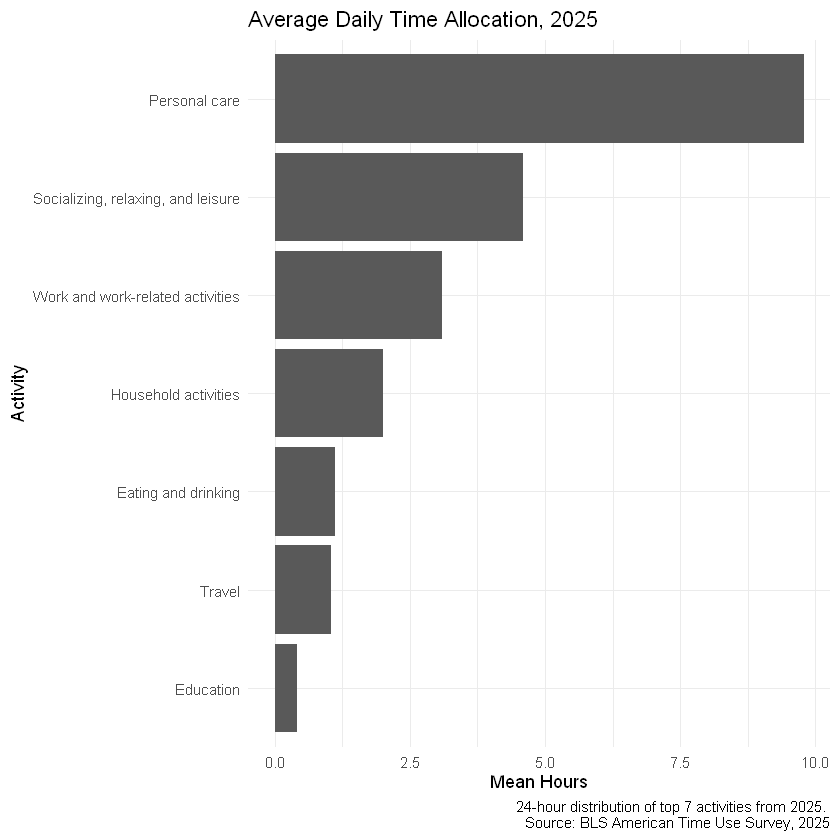

In [12]:
# Visualization 1A: Single-year time allocation
tier1_2025 |>
  slice_max(order_by = mean_hours, n = 7) |>
  ggplot(
    aes(x = mean_hours, y = reorder(activity_label, mean_hours))
  ) +
  geom_col() +
  labs(
    title = "Average Daily Time Allocation, 2025",
    x = "Mean Hours",
    y = "Activity",
    caption = "24-hour distribution of top 7 activities from 2025. 
    Source: BLS American Time Use Survey, 2025"
  ) +
  theme_minimal()

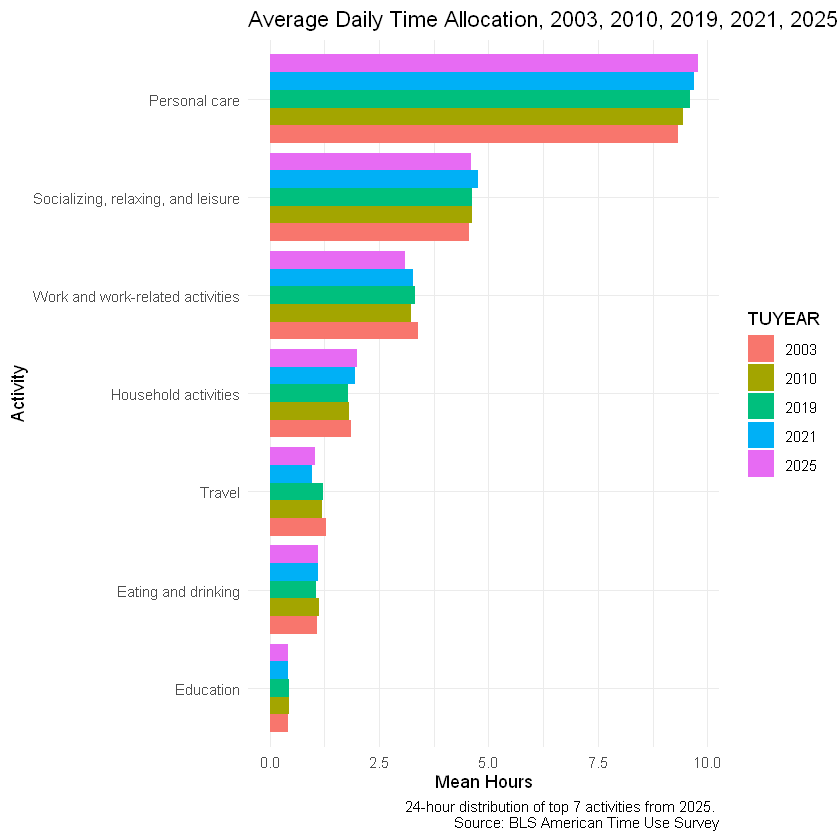

In [13]:
# Visualization 1B: Comparison between years

tier1_selected_years <- annual_tier1_long |>
  filter(TUYEAR %in% c(2003, 2010, 2019, 2021, 2025)) |>
  mutate(
    TUYEAR = factor(TUYEAR)
  )

top_categories <- tier1_selected_years |>
  group_by(activity_label) |>
  summarize(total_val = sum(mean_hours)) |>
  slice_max(order_by = total_val, n = 7, with_ties = FALSE) |>
  pull(activity_label)


tier1_selected_years |>
  filter(activity_label %in% top_categories) |>
  ggplot(
    aes(x = mean_hours, y = reorder(activity_label, mean_hours), fill = TUYEAR)
  ) +
  geom_col(position = "dodge") +
  labs(
    title = "Average Daily Time Allocation, 2003, 2010, 2019, 2021, 2025",
    x = "Mean Hours",
    y = "Activity",
    caption = "24-hour distribution of top 7 activities from 2025. 
    Source: BLS American Time Use Survey"
  ) +
  theme_minimal()

### Historical Trends

Investigate how much average daily time spent in each first-tier activity category has changed from 2003 to 2025.
(2020 is excluded because of interrupted data collection)
